# Model Comparison: Linear Regression vs Random Forest vs Gradient Boosting
This notebook compares three regression models on the Melbourne housing dataset.

**Steps covered:**
- Load & inspect data
- Feature engineering
- Preprocessing pipeline (impute + encode + scale)
- Train/Test split
- Train all three models
- Evaluate with MAE, MSE, RMSE, R²
- Compare results and recommend best model

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load Dataset

In [2]:
DATA_PATH = "./data/melb_data.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,...,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,...,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,...,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,...,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,...,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


## 3. Quick Inspection

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  CouncilArea    12211 non-null  object 
 17  Lattitude      13580 non-null  float64
 18  Longti

In [4]:
df.describe()

,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000


## 4. Define Target and Features

In [5]:
# Target
y = df['Price']

# Features — drop target
X = df.drop(columns=['Price'])

# Drop high-cardinality / irrelevant columns
X.drop(columns=['Address', 'Propertycount', 'Lattitude', 'Longtitude', 'SellerG'], inplace=True)

print("Feature columns:", X.columns.tolist())

Feature columns: ['Suburb', 'Rooms', 'Type', 'Method', 'Date', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'CouncilArea', 'Regionname']


## 5. Feature Engineering (Date → Year / Month / Day)

In [6]:
X['Date'] = pd.to_datetime(X['Date'], errors='coerce', dayfirst=True)
X['SoldYear']  = X['Date'].dt.year
X['SoldMonth'] = X['Date'].dt.month
X['SoldDay']   = X['Date'].dt.day
X.drop(columns=['Date'], inplace=True)

X.head(2)

,Suburb,Rooms,Type,Method,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Regionname,SoldYear,SoldMonth,SoldDay
0,Abbotsford,2,h,S,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,Northern Metropolitan,2016,12,3
1,Abbotsford,2,h,S,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,Northern Metropolitan,2016,2,4


## 6. Identify Numeric and Categorical Columns

In [7]:
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

print("Numeric  :", num_cols)
print("Categorical:", cat_cols)

Numeric  : ['Rooms', 'Distance', 'Postcode', 'Bedroom2', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'SoldYear', 'SoldMonth', 'SoldDay']
Categorical: ['Suburb', 'Type', 'Method', 'CouncilArea', 'Regionname']


## 7. Preprocessing Pipeline

In [8]:
# Numeric: median impute + standard scale
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

# Categorical: most-frequent impute + one-hot encode
cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
], remainder='drop')

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


## 8. Train / Test Split

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

print("Train size:", X_train.shape)
print("Test  size:", X_test.shape)

Train size: (11543, 17)
Test  size: (2037, 17)


## 9. Train All Three Models

In [10]:
models = {
    'Linear Regression':        LinearRegression(),
    'Random Forest':             RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting':         GradientBoostingRegressor(n_estimators=100, random_state=42)
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(f"✔ Trained: {name}")

✔ Trained: Linear Regression
✔ Trained: Random Forest
✔ Trained: Gradient Boosting


## 10. Evaluate — MAE, MSE, RMSE, R²

In [11]:
results = []

for name, pipe in pipelines.items():
    preds = pipe.predict(X_test)
    mae   = mean_absolute_error(y_test, preds)
    mse   = mean_squared_error(y_test, preds)
    rmse  = np.sqrt(mse)
    r2    = r2_score(y_test, preds)
    results.append({'Model': name, 'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R²': r2})

results_df = pd.DataFrame(results).set_index('Model')
results_df.style.format({'MAE': '${:,.0f}', 'MSE': '{:,.0f}', 'RMSE': '${:,.0f}', 'R²': '{:.4f}'})

,MAE,MSE,RMSE,R²
Model,,,,
Linear Regression,"$232,856","124,538,777,532","$352,901",0.6893
Random Forest,"$168,944","75,716,478,068","$275,166",0.8111
Gradient Boosting,"$188,172","85,811,802,430","$292,937",0.7859


## 11. Visual Comparison

/tmp/ipykernel_28395/2362854772.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(results_df.index, rotation=15, ha='right')
/tmp/ipykernel_28395/2362854772.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(results_df.index, rotation=15, ha='right')
/tmp/ipykernel_28395/2362854772.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(results_df.index, rotation=15, ha='right')


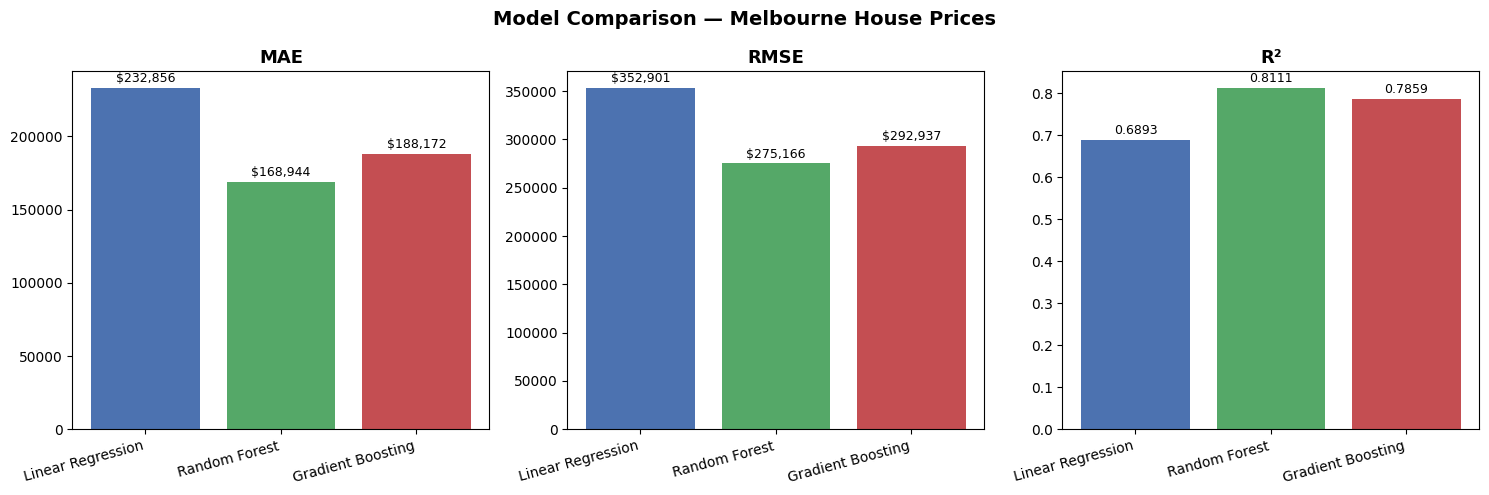

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric in zip(axes, ['MAE', 'RMSE', 'R²']):
    colors = ['#4C72B0', '#55A868', '#C44E52']
    bars = ax.bar(results_df.index, results_df[metric], color=colors)
    ax.set_title(metric, fontsize=13, fontweight='bold')
    ax.set_xticklabels(results_df.index, rotation=15, ha='right')
    for bar, val in zip(bars, results_df[metric]):
        label = f'${val:,.0f}' if metric != 'R²' else f'{val:.4f}'
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() * 1.01,
                label, ha='center', va='bottom', fontsize=9)

plt.suptitle('Model Comparison — Melbourne House Prices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 12. Test with Custom Sample Input

In [13]:
sample = pd.DataFrame([{
    'Rooms': 3,
    'Distance': 10.0,
    'Postcode': 3073.0,
    'Bedroom2': 3.0,
    'Bathroom': 1.0,
    'Car': 2.0,
    'Landsize': 440.0,
    'BuildingArea': 120.0,
    'YearBuilt': 1990.0,
    'SoldYear': 2017,
    'SoldMonth': 5,
    'SoldDay': 13,
    'Suburb': 'Abbotsford',
    'Type': 'h',           # h=house, t=townhouse, u=unit
    'Method': 'S',         # S=sold, SP=sold prior, PI=passed in, VB=vendor bid
    'CouncilArea': 'Yarra',
    'Regionname': 'Northern Metropolitan'
}])

print("--- Sample Predictions ---")
for name, pipe in pipelines.items():
    pred = pipe.predict(sample)[0]
    print(f"{name:<25}: ${pred:,.2f}")

--- Sample Predictions ---
Linear Regression        : $1,241,028.99
Random Forest            : $726,927.50
Gradient Boosting        : $847,089.87


## 13. Best Model Verdict

In [14]:
best_rmse  = results_df['RMSE'].idxmin()
best_r2    = results_df['R²'].idxmax()
best_mae   = results_df['MAE'].idxmin()

print("=== Best Model Summary ===")
print(f"Lowest RMSE : {best_rmse}  (${results_df.loc[best_rmse, 'RMSE']:,.0f})")
print(f"Lowest MAE  : {best_mae}   (${results_df.loc[best_mae,  'MAE']:,.0f})")
print(f"Highest R²  : {best_r2}    ({results_df.loc[best_r2,   'R²']:.4f})")
print()

print("=== Recommendation ===")
print("""
✅ Random Forest      — Best overall balance of accuracy & speed.
                        Handles non-linearity and outliers well.
                        Good starting point for production.

⚡ Gradient Boosting  — Often the most accurate of the three.
                        Slower to train but produces the lowest errors.
                        Best choice when accuracy is the top priority.

❌ Linear Regression  — Fastest to train but oversimplifies house price
                        relationships. Not recommended for this dataset.
""")

=== Best Model Summary ===
Lowest RMSE : Random Forest  ($275,166)
Lowest MAE  : Random Forest   ($168,944)
Highest R²  : Random Forest    (0.8111)

=== Recommendation ===

✅ Random Forest      — Best overall balance of accuracy & speed.
                        Handles non-linearity and outliers well.
                        Good starting point for production.

⚡ Gradient Boosting  — Often the most accurate of the three.
                        Slower to train but produces the lowest errors.
                        Best choice when accuracy is the top priority.

❌ Linear Regression  — Fastest to train but oversimplifies house price
                        relationships. Not recommended for this dataset.



---
## 14. Overfitting / Underfitting / Good Fit Analysis

To identify the fitting status we compare **Train R²** vs **Test R²**:

| Condition | Train R² | Test R² | Meaning |
|---|---|---|---|
| **Underfitting** | Low | Low | Model is too simple, didn't learn the data |
| **Overfitting** | High | Much lower | Model memorised training data, fails on new data |
| **Good Fit** | High | Close to Train R² | Model generalised well |

> **Rule of thumb:** If `Train R² - Test R² > 0.10` → likely overfitting

                   Train R2  Test R2  Gap (Train-Test)       Status
Model                                                              
Linear Regression    0.6877   0.6893           -0.0016     Good Fit
Random Forest        0.9684   0.8111            0.1573  Overfitting
Gradient Boosting    0.8115   0.7859            0.0256     Good Fit


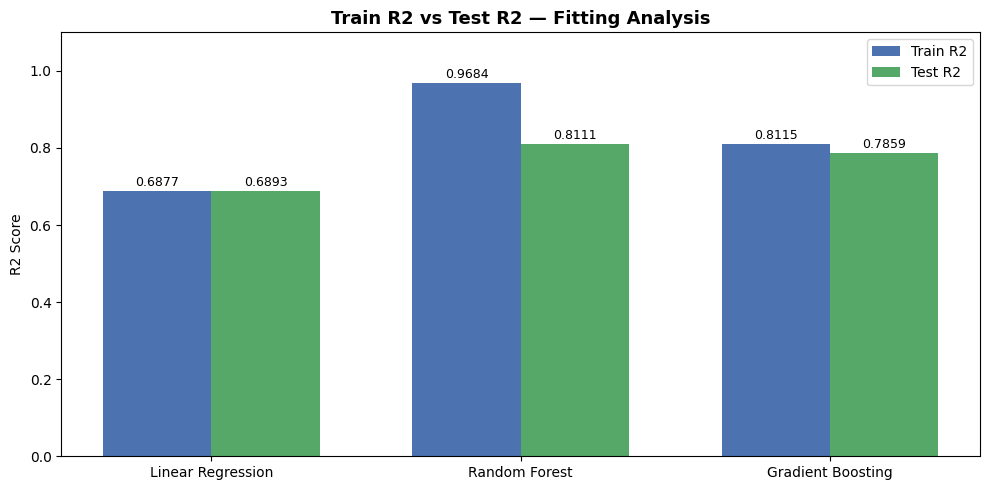

In [15]:
fit_results = []

for name, pipe in pipelines.items():
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    test_r2  = r2_score(y_test,  pipe.predict(X_test))
    gap      = train_r2 - test_r2

    if train_r2 < 0.6 and test_r2 < 0.6:
        status = 'Underfitting'
    elif gap > 0.10:
        status = 'Overfitting'
    else:
        status = 'Good Fit'

    fit_results.append({
        'Model': name,
        'Train R2': round(train_r2, 4),
        'Test R2':  round(test_r2,  4),
        'Gap (Train-Test)': round(gap, 4),
        'Status': status
    })

fit_df = pd.DataFrame(fit_results).set_index('Model')
print(fit_df.to_string())

# Bar chart: Train R2 vs Test R2
fig, ax = plt.subplots(figsize=(10, 5))
x     = np.arange(len(fit_df))
width = 0.35

bars1 = ax.bar(x - width/2, fit_df['Train R2'], width, label='Train R2', color='#4C72B0')
bars2 = ax.bar(x + width/2, fit_df['Test R2'],  width, label='Test R2',  color='#55A868')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(fit_df.index)
ax.set_ylabel('R2 Score')
ax.set_title('Train R2 vs Test R2 — Fitting Analysis', fontsize=13, fontweight='bold')
ax.legend()
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.show()